## Notebook to visualize attention between 2 graphs

In [143]:
import sys, os, glob
sys.path.insert(0, os.path.abspath('src'))  

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import seaborn as sns
import pandas as pd

from src.graphmatchingnetwork import GraphMatchingNetwork

In [144]:
# --- Configurazione ---
CHECKPOINT    = "lightning_logs/gmn_model/version_1/best.ckpt"
CHECKPOINT = "checkpoint/gmn_best_1_layer.ckpt"
PROCESSED_DIR = "data/processed"
CSV_PATH = "data/raw/PL_cleaned_index.csv"

# Scegli il complesso da visualizzare
pt_files  = glob.glob(os.path.join(PROCESSED_DIR, "protein_*.pt"))
pdb_codes = sorted([os.path.basename(f).replace("protein_", "").replace(".pt", "") for f in pt_files])
print(f"Complessi disponibili: {len(pdb_codes)}")

PDB_CODE = pdb_codes[45]   # ← cambia qui per un complesso diverso
print(f"Complesso selezionato: {PDB_CODE}")

Complessi disponibili: 4851
Complesso selezionato: 1b0h


In [145]:
# --- Carica modello dal checkpoint ---
model = GraphMatchingNetwork.load_from_checkpoint(CHECKPOINT, map_location='cpu')
model.eval()
print(dict(model.hparams))

c:\Users\andre\Desktop\ANDREA\POLIMI\LEONARDO\Bio_Graph_ML\GML_repo\.venv\Lib\site-packages\pytorch_lightning\utilities\migration\utils.py:56: The loaded checkpoint was produced with Lightning v2.6.5, which is newer than your current Lightning version: v2.6.1


{'token_dim': 64, 'node_embedding_dims': [32, 16], 'edge_embedding_dims': [32, 16], 'num_layers': 1, 'lr': 0.0006, 'dropout_p': 0.12, 'normalization': True}


In [146]:
# --- Carica il complesso scelto ---
prot = torch.load(os.path.join(PROCESSED_DIR, f"protein_{PDB_CODE}.pt"), weights_only=False)
lig  = torch.load(os.path.join(PROCESSED_DIR, f"ligand_{PDB_CODE}.pt"),  weights_only=False)


# Batch vector: un solo grafo (tutti zero) - simulo una batch 
prot.batch = torch.zeros(prot.x.shape[0], dtype=torch.long)
lig.batch  = torch.zeros(lig.x.shape[0],  dtype=torch.long)

n_prot = prot.x.shape[0]
n_lig  = lig.x.shape[0]
print(f"Proteina : {n_prot} residui | {prot.edge_index.shape[1]//2} archi")
print(f"Ligando  : {n_lig} atomi   | {lig.edge_index.shape[1]//2} archi")
print(f"pAffinity: {prot.y.item():.3f}")

Proteina : 517 residui | 3171 archi
Ligando  : 34 atomi   | 206 archi
pAffinity: 6.699


In [ ]:
#grafo proteina
from src.protein import Protein

protein = Protein.from_pdb_code(PDB_CODE)
protein.visualize_protein_graph()

Output()

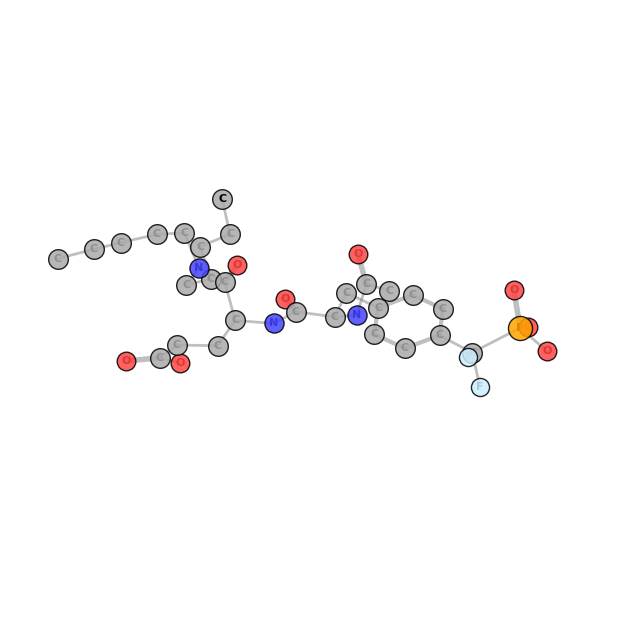

In [ ]:
#grafo ligando
from src.ligand import Ligand
df=pd.read_csv(CSV_PATH)
smile=df[df['pdb_code']==PDB_CODE]['SMILE'].values[0]
release_year=df[df['pdb_code']==PDB_CODE]['release_year'].values[0]
ligand=Ligand.from_smile(smiles=smile)
ligand.visualize_nx3D()

In [ ]:
# --- Inference + estrazione attention ---
with torch.no_grad():
    pred, (attn_p_to_l, attn_l_to_p) = model(prot, lig, return_attention=True)

# Rimuovi dim batch (B=1), converti in numpy
attn_p_to_l = attn_p_to_l[0].numpy()   # [N_prot, N_lig]
attn_l_to_p = attn_l_to_p[0].numpy()   # [N_lig,  N_prot]

print(f"Predizione pAffinity : {pred.item():.3f}")
print(f"Reale pAffinity      : {prot.y.item():.3f}")
print(f"attn_p_to_l : {attn_p_to_l.shape}  (somma righe ≈ 1: {attn_p_to_l.sum(axis=1).mean():.3f})")
print(f"attn_l_to_p : {attn_l_to_p.shape}")

Predizione pAffinity : 6.126
Reale pAffinity      : 5.620
attn_p_to_l : (105, 41)  (somma righe ≈ 1: 1.000)
attn_l_to_p : (41, 105)


In [ ]:
# --- Etichette nodi ---
AMINO_ACIDS = ['ALA','ARG','ASN','ASP','CYS','GLN','GLU','GLY','HIS','ILE',
               'LEU','LYS','MET','PHE','PRO','SER','THR','TRP','TYR','VAL','UNK']

ATOMIC_SYM  = {1:'H',6:'C',7:'N',8:'O',9:'F',15:'P',16:'S',17:'Cl',35:'Br',53:'I'}

#label protein - SER0 ILE1 GLN2
aa_codes  = prot.x[:, 8].long().tolist()
prot_labels = [f"{AMINO_ACIDS[min(c, 20)]}{i}" for i, c in enumerate(aa_codes)]

#label ligand - O0 C1 C3 P4
atom_nums = lig.x[:, 0].long().tolist()
lig_labels  = [f"{ATOMIC_SYM.get(n, f'Z{n}')}{i}" for i, n in enumerate(atom_nums)]

print("Primi 5 residui :", prot_labels[:5])
print("Primi 5 atomi   :", lig_labels[:5])

Primi 5 residui : ['SER0', 'ILE1', 'GLN2', 'ALA3', 'GLU4']
Primi 5 atomi   : ['O0', 'C1', 'C2', 'P3', 'F4']


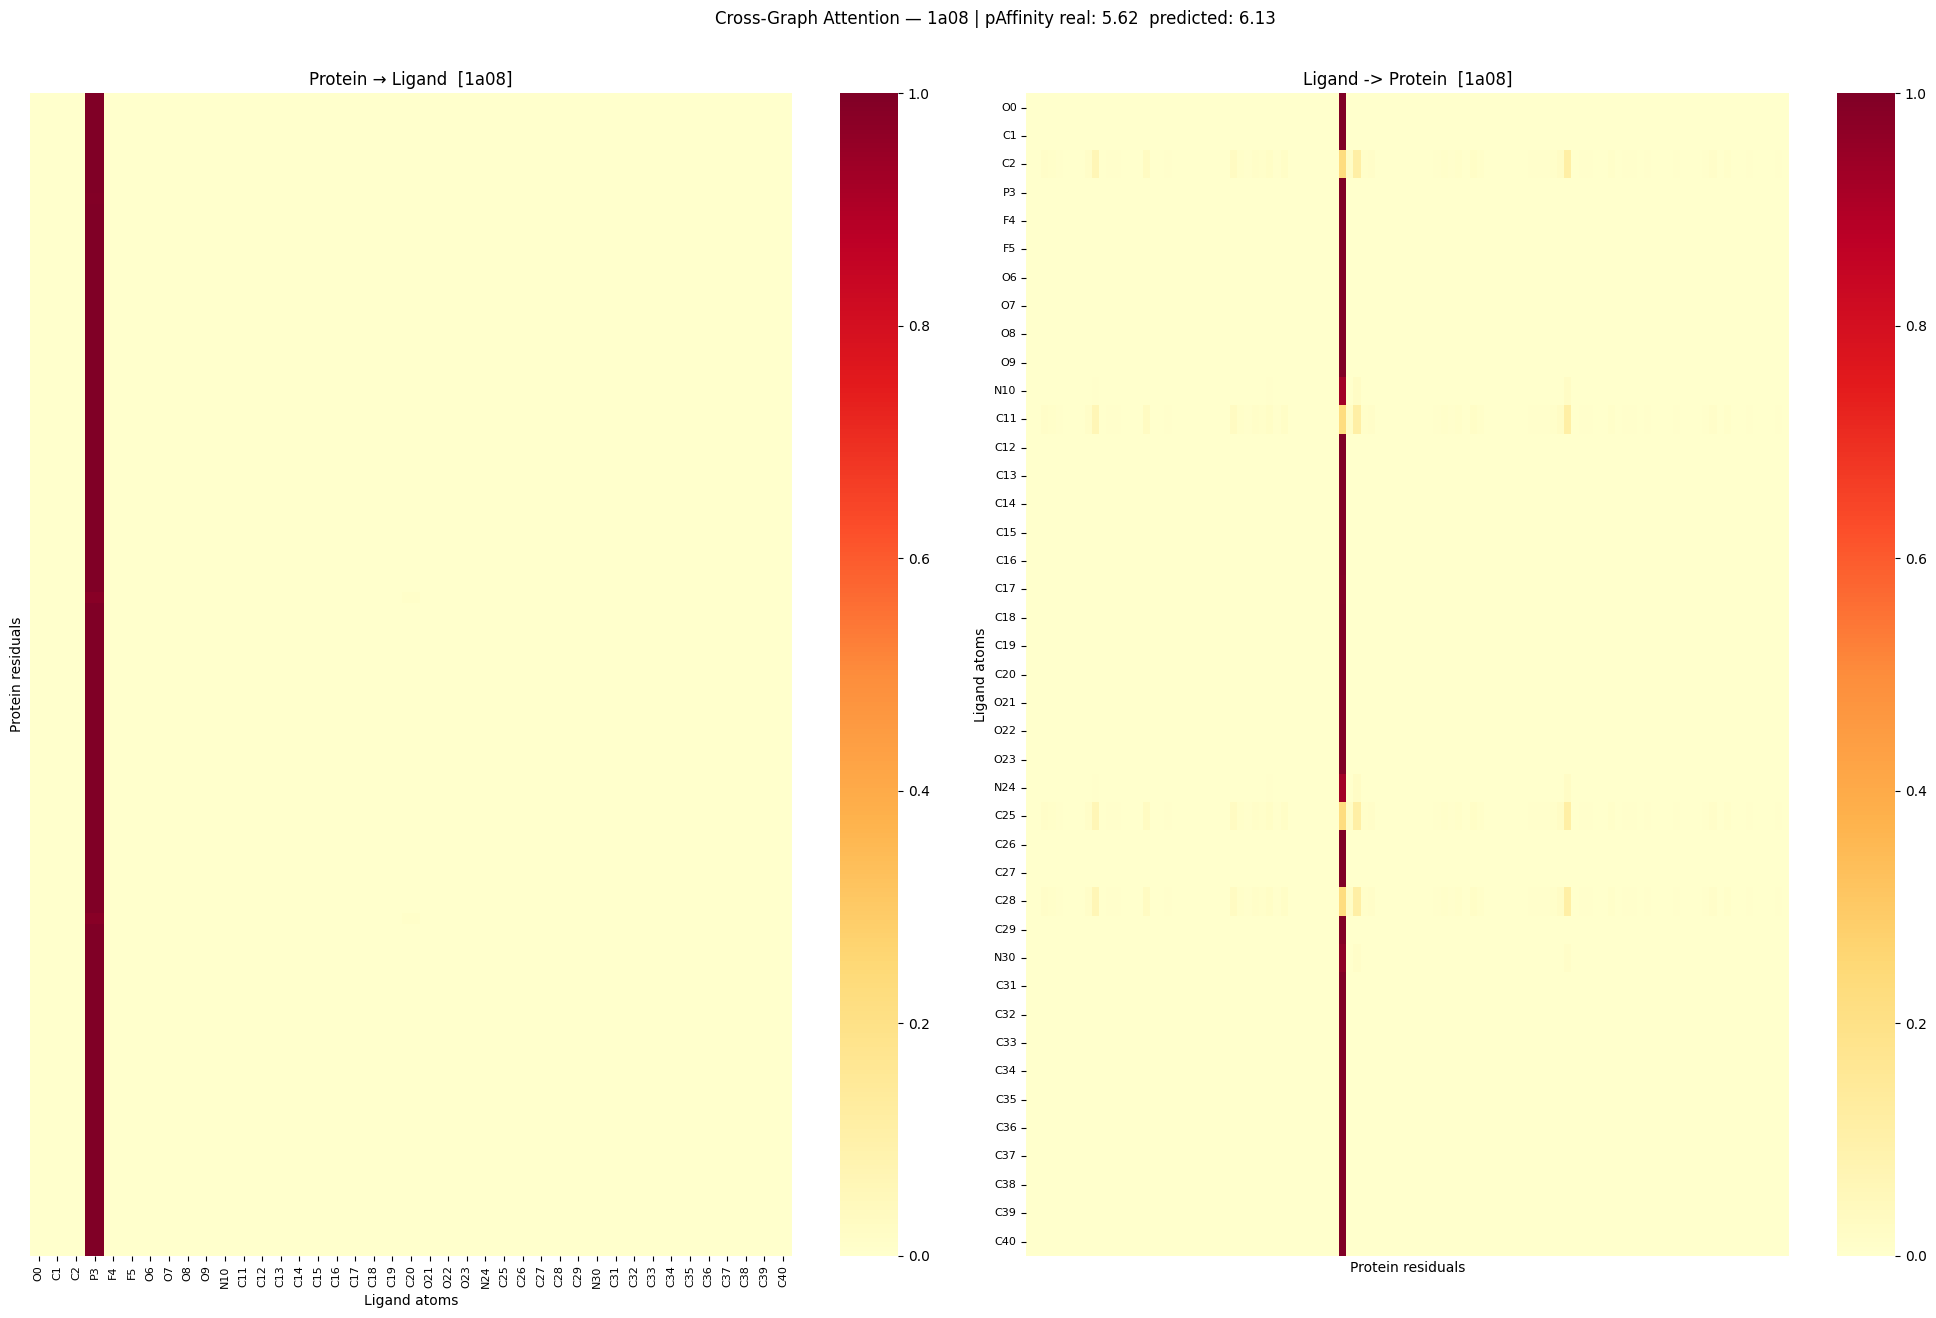

In [ ]:
# --- Heatmap bidirezionale ---
fig, axes = plt.subplots(1, 2, figsize=(20, max(6, n_prot // 8)))

# Proteina → Ligando  [N_prot × N_lig]
ax = axes[0]
sns.heatmap(attn_p_to_l, ax=ax, cmap='YlOrRd', cbar=True,
            xticklabels=lig_labels,
            yticklabels=prot_labels if n_prot <= 80 else False)
ax.set_xlabel('Ligand atoms')
ax.set_ylabel('Protein residuals')
ax.set_title(f'Protein → Ligand  [{PDB_CODE}]')
ax.tick_params(axis='x', labelsize=8, rotation=90)
ax.tick_params(axis='y', labelsize=6)

# Ligando → Proteina  [N_lig × N_prot]
ax = axes[1]
sns.heatmap(attn_l_to_p, ax=ax, cmap='YlOrRd', cbar=True,
            xticklabels=prot_labels if n_prot <= 80 else False,
            yticklabels=lig_labels)
ax.set_xlabel('Protein residuals')
ax.set_ylabel('Ligand atoms')
ax.set_title(f'Ligand -> Protein  [{PDB_CODE}]')
ax.tick_params(axis='x', labelsize=6, rotation=90)
ax.tick_params(axis='y', labelsize=8)

plt.suptitle(
    f'Cross-Graph Attention — {PDB_CODE} | pAffinity real: {prot.y.item():.2f}  predicted: {pred.item():.2f}',
    fontsize=12, y=1.01)
plt.tight_layout()
#plt.savefig(f'attention_{PDB_CODE}_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

[Protein -> Ligand] - 214 visualized archs.
[Ligand -> Protein] - 215 visualized archs.


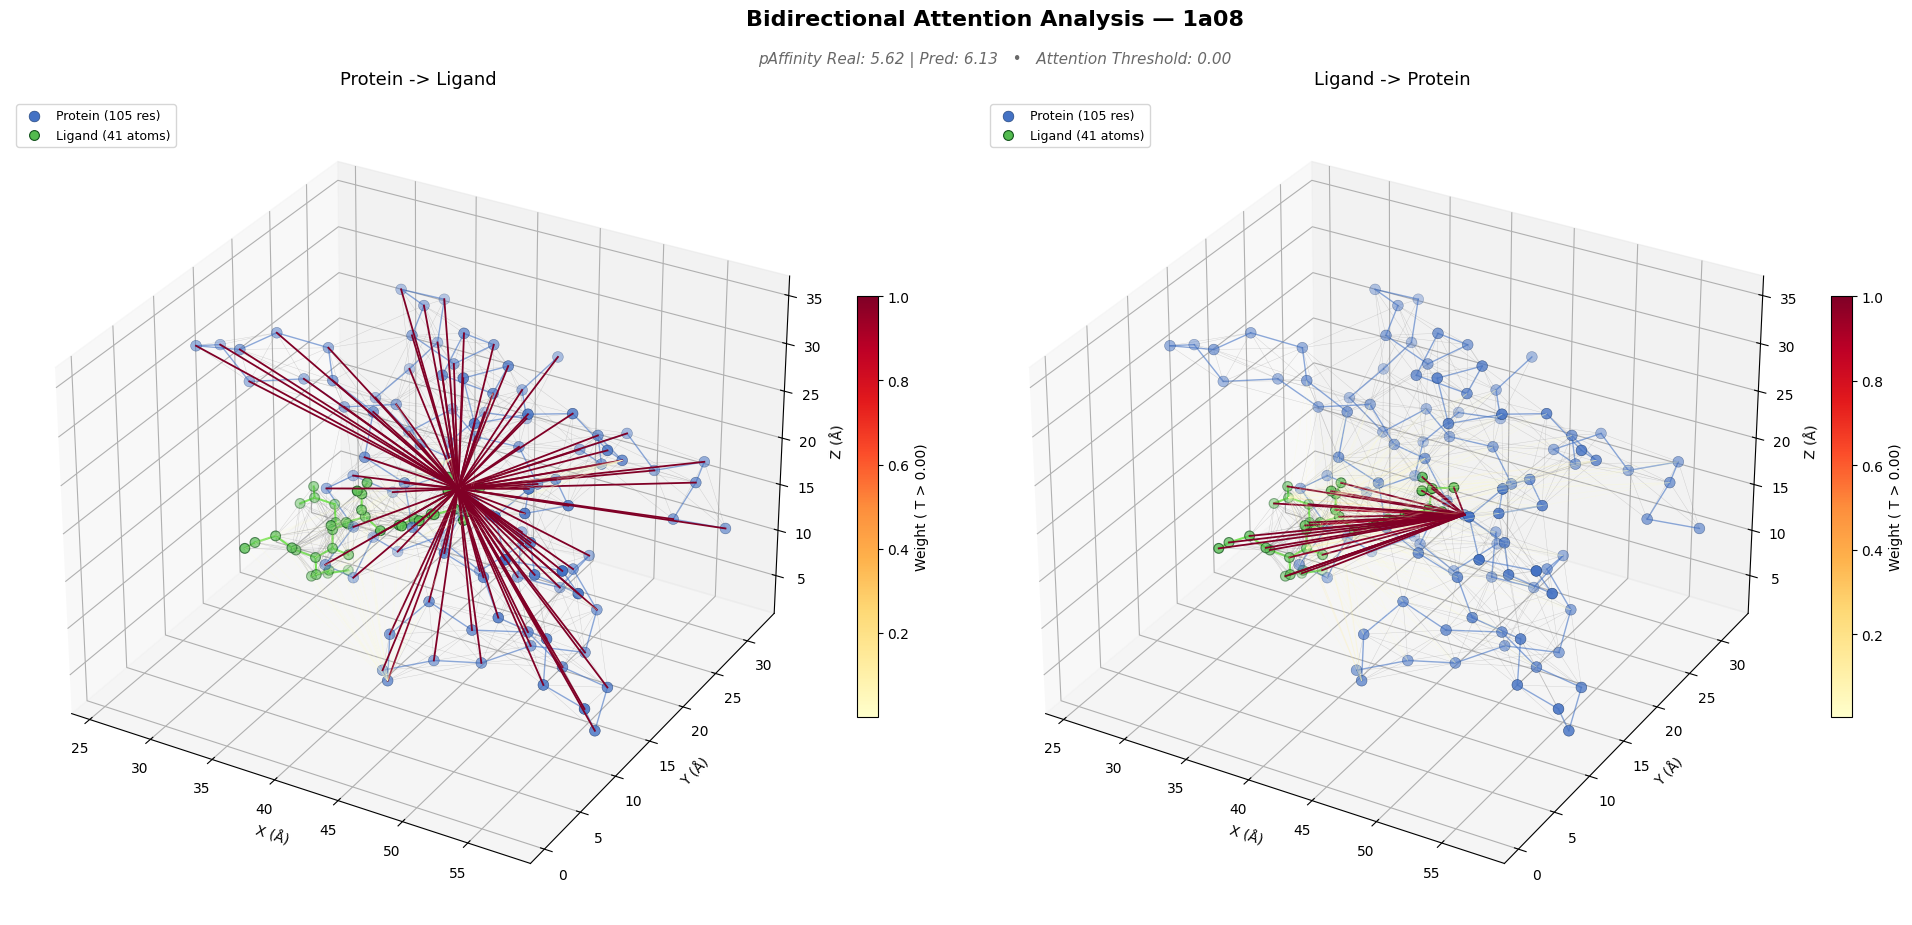

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import numpy as np
import matplotlib.pyplot as plt

top_percentage=5

pos_prot = prot.pos.cpu().numpy()  # [N_prot, 3]
pos_lig  = lig.pos.cpu().numpy()   # [N_lig,  3]

# Aumentiamo la larghezza della figura per ospitare due grafici 3D
fig = plt.figure(figsize=(20, 10))

# Definiamo le configurazioni per i due subplot
configs = [
    {
        'subplot_idx': 121, # 1 riga, 2 colonne, indice 1 (sinistra)
        'attn': attn_p_to_l, 
        'is_p2l': True, 
        'title': 'Protein -> Ligand'
    },
    {
        'subplot_idx': 122, # 1 riga, 2 colonne, indice 2 (destra)
        'attn': attn_l_to_p, 
        'is_p2l': False, 
        'title': 'Ligand -> Protein'
    }
]


for cfg in configs:
    ax = fig.add_subplot(cfg['subplot_idx'], projection='3d')
    attn = cfg['attn']
    
    THRESHOLD = np.percentile(attn, 100-top_percentage)
    
    # --- 1. Proteina: cerchi blu e legami ---
    ax.scatter(pos_prot[:, 0], pos_prot[:, 1], pos_prot[:, 2],
               c='#4472C4', s=60, edgecolors='#1a3a6e', linewidths=0.4,
               depthshade=True, label=f'Protein ({n_prot} res)', zorder=2)

    seen = set()
    for k, (src, dst) in enumerate(prot.edge_index.t().numpy()):
        e = tuple(sorted((int(src), int(dst))))
        if e in seen:
            continue
        seen.add(e)
        p1, p2 = pos_prot[src], pos_prot[dst]
        if prot.edge_attr[k, 0].item() == 1.0:   # peptide bond
            ax.plot([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]],
                    color="#4473C4C2", linewidth=1, alpha=0.6)
        else:                                    # contatto spaziale
            ax.plot([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]],
                    color="#929191", linewidth=0.3, alpha=0.4)

    # --- 2. Ligando: cerchi verdi e legami ---
    ax.scatter(pos_lig[:, 0], pos_lig[:, 1], pos_lig[:, 2],
               c="#53BB4F", s=50, edgecolors="#13521C", linewidths=0.8,
               marker='o', depthshade=True, label=f'Ligand ({n_lig} atoms)', zorder=3)

    seen_l = set()
    for k, (src, dst) in enumerate(lig.edge_index.t().numpy()):
        e = tuple(sorted((int(src), int(dst))))
        if e in seen_l:
            continue
        seen_l.add(e)
        p1, p2 = pos_lig[src], pos_lig[dst]
        if lig.edge_attr[k, 0] != 0.0:
            ax.plot([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]],
                    color="#4CDF1F", linewidth=1.5, alpha=0.7)
        else:
            ax.plot([p1[0],p2[0]], [p1[1],p2[1]], [p1[2],p2[2]],
                    color="#929191", linewidth=0.3, alpha=0.4)

    # --- 3. Archi attention sopra soglia (Logica Dinamica) ---
    edge_pairs, edge_weights_all = [], []
    
    for i in range(attn.shape[0]):
        for j in range(attn.shape[1]):
            w = float(attn[i, j])
            if w > THRESHOLD:
                edge_pairs.append((i, j))
                edge_weights_all.append(w)

    if edge_pairs:
        norm     = Normalize(vmin=THRESHOLD, vmax=max(edge_weights_all))
        cmap_att = plt.cm.YlOrRd
        for (i, j), w in zip(edge_pairs, edge_weights_all):
            
            # Assegnazione corretta delle coordinate in base alla direzione
            if cfg['is_p2l']:
                p1, p2 = pos_prot[i], pos_lig[j]
            else:
                p1, p2 = pos_lig[i], pos_prot[j]
                
            color  = cmap_att(norm(w))
            ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]],
                    color=color, linewidth=0.5 + 0.8 * norm(w),
                    alpha=0.2 + 0.8 * norm(w), zorder=4)
                    
        sm = ScalarMappable(cmap=cmap_att, norm=norm)
        sm.set_array([])
        plt.colorbar(sm, ax=ax, shrink=0.45, pad=0.03,
                     label=f'Weight ( T > {THRESHOLD:.2f})')
        print(f"[{cfg['title']}] - {len(edge_pairs)} visualized archs.")
    else:
        print(f"[{cfg['title']}] - no archs above treshold {THRESHOLD:.2f}.")

    # --- 4. Aspect ratio reale e formattazione ---
    all_pos   = np.vstack([pos_prot, pos_lig])
    max_range = (all_pos.max(axis=0) - all_pos.min(axis=0)).max() / 2.0
    mid       = (all_pos.max(axis=0) + all_pos.min(axis=0)) / 2.0
    ax.set_xlim(mid[0]-max_range, mid[0]+max_range)
    ax.set_ylim(mid[1]-max_range, mid[1]+max_range)
    ax.set_zlim(mid[2]-max_range, mid[2]+max_range)

    ax.set_title(f"{cfg['title']}", fontsize=13, pad=10)
    ax.set_xlabel('X (Å)'); ax.set_ylabel('Y (Å)'); ax.set_zlabel('Z (Å)')
    ax.legend(fontsize=9, markerscale=1.0, loc='upper left')

# Render finale
fig.suptitle(f'Bidirectional Attention Analysis — {PDB_CODE}', fontsize=16, fontweight='bold')
# 2. Sottotitolo con pAffinity Real vs Pred e Threshold
fig.text(
    0.5, 
    0.93, 
    f'pAffinity Real: {prot.y.item():.2f} | Pred: {pred.item():.2f}   •   Attention Threshold: {THRESHOLD:.2f}', 
    style='italic',
    ha='center',
    va='center',
    fontsize=11,
    color='dimgray'
)
plt.tight_layout()
plt.show()

In [ ]:
import py3Dmol
import numpy as np
import torch

# --- 1. PREPARAZIONE DATI ---
p_to_l = True
if p_to_l:
    pos_p = prot.pos.cpu().numpy()
    pos_l = lig.pos.cpu().numpy()
    attn  = attn_p_to_l   # [N_prot, N_lig]
else:
    pos_l = prot.pos.cpu().numpy()
    pos_p = lig.pos.cpu().numpy()
    attn  = attn_l_to_p   # [N_lig, N_prot]



SDF_PATH = f"./data/raw/P-L/{release_year}/{PDB_CODE}/{PDB_CODE}_ligand.sdf"
PDB_PATH = f"./data/raw/P-L/{release_year}/{PDB_CODE}/{PDB_CODE}_protein.pdb"
with open(PDB_PATH, 'r') as f:
    pdb_data = f.read()

with open(SDF_PATH, 'r') as f:
    sdf_data = f.read() 
    
# --- 2. VIEWER E CARICAMENTO ---
view = py3Dmol.view(width=900, height=600, data=pdb_data)
view.addModel(sdf_data, 'sdf')   

view.setStyle({}, {}) 
view.setBackgroundColor('white')    

# --- 3. STILE PROTEINA ---
view.setStyle(  
    {'model': 0}, 
    #{'stick': {'colorscheme': 'element', 'radius': 0.1}},
)
view.addSurface(
    py3Dmol.VDW,                                   
    {'opacity': 0.7, 'color': 'white'} ,        
    {'model': 0}, 
)

# --- 4. STILE LIGANDO SDF (Modello 1) ---
view.setStyle({'model': 1}, {
    'stick':  {'colorscheme': 'greenCarbon', 'radius': 0.15,'opacity':0.2},
    'sphere': {'colorscheme': 'greenCarbon', 'scale': 0.20,'opacity':0.2},
})
view.addSurface(
    py3Dmol.VDW, 
    {'opacity': 0.5, 'type': 'mesh','color': 'cyan'},
    {'model': 1}
)
# --- 5. FILTRAGGIO E NORMALIZZAZIONE ATTENTION ---
attn_max = attn.max()
attn_min = attn.min()
attn_norm = (attn - attn_min) / (attn_max - attn_min)

threshold = 0.75
max_radius = 0.03

for i in range(pos_p.shape[0]):
    for j in range(pos_l.shape[0]):
        weight = float(attn_norm[i, j])
        
        if weight > threshold:
            start_coord = {"x": float(pos_p[i, 0]), "y": float(pos_p[i, 1]), "z": float(pos_p[i, 2])}
            end_coord = {"x": float(pos_l[j, 0]), "y": float(pos_l[j, 1]), "z": float(pos_l[j, 2])}
            
            din_radius = weight * max_radius
            view.addCylinder({
                "start": start_coord,
                "end": end_coord,
                "radius": din_radius,
                "color": "purple",      # Colore viola/magenta per staccare dal bianco e dal verde
                "dashed": True,         # Stile tratteggiato tipico delle interazioni/legami non covalenti
                "opacity": 1       # Più è importante, più il legame è marcato e visibile
            })

# --- 6. RENDER: zoom centrato sul sito di binding ---
view.zoomTo({'model': 1})
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
import py3Dmol
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# --- 1. PREPARAZIONE DATI ---
p_to_l = True
if p_to_l:
    pos_p = prot.pos.cpu().numpy()
    pos_l = lig.pos.cpu().numpy()
    attn  = attn_p_to_l   # [N_prot, N_lig]
else:
    pos_p = lig.pos.cpu().numpy()
    pos_l = prot.pos.cpu().numpy()
    attn  = attn_l_to_p   # [N_lig, N_prot]

SDF_PATH = f"./data/raw/P-L/{release_year}/{PDB_CODE}/{PDB_CODE}_ligand.sdf"
PDB_PATH = f"./data/raw/P-L/{release_year}/{PDB_CODE}/{PDB_CODE}_protein.pdb"
with open(PDB_PATH, 'r') as f:
    pdb_data = f.read()
with open(SDF_PATH, 'r') as f:
    sdf_data = f.read()

# --- 2. VIEWER E CARICAMENTO ---
view = py3Dmol.view(width=900, height=600, data=pdb_data)
view.addModel(sdf_data, 'sdf')
view.setStyle({}, {})
view.setBackgroundColor('white')

# --- 3. STILE PROTEINA ---
view.setStyle({'model': 0}, {'stick': {'colorscheme': 'element', 'radius': 0.1}})
view.addSurface(py3Dmol.MS, {'opacity': 0.5, 'color': 'white'}, {'model': 0})

# --- 4. STILE LIGANDO SDF (Modello 1) ---
view.setStyle({'model': 1}, {
    'stick':  {'colorscheme': 'greenCarbon', 'radius': 0.15},
    'sphere': {'colorscheme': 'greenCarbon', 'scale': 0.20}
})
view.addSurface(py3Dmol.VDW, {'opacity': 0.1, 'color': 'cyan'}, {'model': 1})

# --- 5. ATTENTION: opacity=1 sempre per compatibilità con il depth buffer delle superfici ---
# Il depth buffer WebGL blocca i cilindri con opacity<1 quando ci sono superfici.
# La variabilità visiva viene codificata interamente tramite colore (YlOrRd) e raggio.
if isinstance(attn, torch.Tensor):
    attn = attn.detach().cpu().numpy()

THRESHOLD = 0.035
attn_max  = float(attn.max())

norm     = mcolors.Normalize(vmin=THRESHOLD, vmax=attn_max)
cmap_att = plt.cm.YlOrRd

RAGGIO_MIN, RAGGIO_MAX = 0.01, 0.05  # Å

for i in range(pos_p.shape[0]):
    for j in range(pos_l.shape[0]):
        w = float(attn[i, j])
        if w <= THRESHOLD:
            continue

        norm_val  = float(norm(w))
        hex_color = mcolors.to_hex(cmap_att(norm_val))
        raggio    = float(RAGGIO_MIN + norm_val * (RAGGIO_MAX - RAGGIO_MIN))

        start = {'x': float(pos_p[i, 0]), 'y': float(pos_p[i, 1]), 'z': float(pos_p[i, 2])}
        end   = {'x': float(pos_l[j, 0]), 'y': float(pos_l[j, 1]), 'z': float(pos_l[j, 2])}

        view.addCylinder({
            'start': start, 'end': end,
            'radius': raggio,
            'color': hex_color,
            'dashed': True,
            'opacity': 1,          # sempre 1: unico modo per passare il depth test delle superfici
        })

# --- 6. RENDER ---
view.zoomTo({'model': 1})
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.